<a href="https://colab.research.google.com/github/finaelfiani/food-waste-data-profiling/blob/main/Assignment1_Food_Waste_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 1: Data Profiling (EDA) Report

## Food Waste Management Dataset

**Industry:** Retail and Food Service

**Scenario:** Data Quality Assessment for Food Waste Management

**Group Members:**
1. FINA ELFIANI BINTI NURFAUZI (A211160)
2. QISTINA BALQIS BINTI ABDUL AZIZ (A211077)
3. WAN NUR HANAA’ BINTI WAN MUHAMMAD HAMKA (A211708)
4. MAISARAH HASYA SYAZWANA BINTI MOHD HELMI (A211488)

## 1. Scenario

Food waste management requires accurate inventory, sales,
and storage information to monitor stock levels and reduce
unnecessary food waste. However, missing values, unusual
quantities, and inconsistent records may affect the
reliability of the data. This project focuses on profiling
and improving the quality of a synthetic food waste dataset
covering supermarkets and other food service businesses.

### Questions
1. What missing values and data quality issues exist in the dataset?
2. Are there unusual values in stock quantities, demand, and food waste records?
3. Is the dataset suitable for supporting food waste monitoring and analysis?

## 2. Data Source

**Dataset Name:** AI-Powered Food Waste Management Dataset

**Source:** Kaggle

**Dataset URL:** https://www.kaggle.com/datasets/vinay24baghira/ai-powered-food-waste-management-dataset-v1


**Dataset Type:** Synthetic data

**Dataset Size:** 8,000 records and 16 attributes

**Files Used:**
- food_waste_dataset.csv
- data_dictionary.csv

**Data Collection Method:**

The dataset was obtained from Kaggle and downloaded in CSV format. It contains simulated daily food inventory records from supermarkets, restaurants, cafeterias, and cloud kitchens. The dataset includes information about inventory, sales, demand, storage conditions, food waste and donations.

The CSV file was imported into Google Colab using the pandas library for data profiling and quality assessment.

## Load the dataset

In [1]:
import pandas as pd

# Load dataset directly from GitHub
url = "https://raw.githubusercontent.com/finaelfiani/food-waste-data-profiling/main/food_waste_dataset.csv"

df = pd.read_csv(url)

# Display dataset overview
print("--- Dataset Overview ---")
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

print("\n--- First 5 Rows ---")
display(df.head())

print("\n--- Column Information ---")
df.info()

--- Dataset Overview ---
Total Rows: 8000
Total Columns: 16

--- First 5 Rows ---


,Inventory_ID,Date,Business_Type,Food_Category,Purchase_Quantity,Units_Sold,Remaining_Stock,Shelf_Life_Days,Storage_Temperature,Daily_Demand,Promotion,Weather,Waste_Quantity,Waste_Reason,Donation_Made,Waste_Level
0,INV000001,2025-01-01,Restaurant,Bakery,77,77,0,4.0,20.4,77.0,No,Sunny,0,No Waste,No,Low
1,INV000002,2025-01-01,Cafeteria,Bakery,75,53,22,3.0,22.8,53.0,No,Cloudy,6,Low Demand,No,Medium
2,INV000003,2025-01-01,Supermarket,Fruits,176,159,17,6.0,12.4,159.0,No,Sunny,4,Expired,No,Medium
3,INV000004,2025-01-01,Cafeteria,Dairy,58,58,0,7.0,3.5,83.0,Yes,Cloudy,0,No Waste,No,Low
4,INV000005,2025-01-01,Restaurant,Fruits,85,85,0,3.0,3.3,87.0,No,Hot,0,No Waste,No,Low



--- Column Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Inventory_ID         8000 non-null   object 
 1   Date                 8000 non-null   object 
 2   Business_Type        8000 non-null   object 
 3   Food_Category        8000 non-null   object 
 4   Purchase_Quantity    8000 non-null   int64  
 5   Units_Sold           8000 non-null   int64  
 6   Remaining_Stock      8000 non-null   int64  
 7   Shelf_Life_Days      7765 non-null   float64
 8   Storage_Temperature  7814 non-null   float64
 9   Daily_Demand         7790 non-null   float64
 10  Promotion            8000 non-null   object 
 11  Weather              7797 non-null   object 
 12  Waste_Quantity       8000 non-null   int64  
 13  Waste_Reason         8000 non-null   object 
 14  Donation_Made        7767 non-null   object 
 15  Waste_Leve

## Check the column names

In [2]:
print("--- Dataset Columns ---")

for i, column in enumerate(df.columns, 1):
    print(f"{i}. {column}")

--- Dataset Columns ---
1. Inventory_ID
2. Date
3. Business_Type
4. Food_Category
5. Purchase_Quantity
6. Units_Sold
7. Remaining_Stock
8. Shelf_Life_Days
9. Storage_Temperature
10. Daily_Demand
11. Promotion
12. Weather
13. Waste_Quantity
14. Waste_Reason
15. Donation_Made
16. Waste_Level


## 3. (a) Missing Values
###Count the missing values

In [3]:
missing_counts = df.isnull().sum()
print("--- Missing Values ---")
print(missing_counts)

--- Missing Values ---
Inventory_ID             0
Date                     0
Business_Type            0
Food_Category            0
Purchase_Quantity        0
Units_Sold               0
Remaining_Stock          0
Shelf_Life_Days        235
Storage_Temperature    186
Daily_Demand           210
Promotion                0
Weather                203
Waste_Quantity           0
Waste_Reason             0
Donation_Made          233
Waste_Level              0
dtype: int64


###Turn it into percentage

In [4]:
missing_pct = (missing_counts / len(df)) * 100
print("--- Missing Values Percentage ---")
print(missing_pct)

--- Missing Values Percentage ---
Inventory_ID           0.0000
Date                   0.0000
Business_Type          0.0000
Food_Category          0.0000
Purchase_Quantity      0.0000
Units_Sold             0.0000
Remaining_Stock        0.0000
Shelf_Life_Days        2.9375
Storage_Temperature    2.3250
Daily_Demand           2.6250
Promotion              0.0000
Weather                2.5375
Waste_Quantity         0.0000
Waste_Reason           0.0000
Donation_Made          2.9125
Waste_Level            0.0000
dtype: float64


In [5]:
missing_table = pd.DataFrame({
    "Missing_Count": missing_counts,
    "Missing_Percentage": missing_pct.round(2)
})

missing_table = missing_table.sort_values(by="Missing_Count", ascending=False)

missing_table = missing_table[missing_table["Missing_Count"] > 0]
display(missing_table)

,Missing_Count,Missing_Percentage
Shelf_Life_Days,235,2.94
Donation_Made,233,2.91
Daily_Demand,210,2.62
Weather,203,2.54
Storage_Temperature,186,2.33


In [6]:
# to check if anything in a row missing
df.isnull().any(axis=1).sum()

np.int64(1006)

In [7]:
# percentage of missing rows
1006 / 8000 * 100

12.575

**Observation**

There are a total of 5 columns with missing values, including Shelf_Life_Days, Donation_Made, Daily_Demand, Weather and Storage_Temperature. Column Shelf_Life_Days has the most missing values, with missing_count (235) and missing_percentage (2.94%).

The missing amount in each columns is quite small. Each column is only slightly missing, but dropping rows would remove around 12.6% of the data (1006 rows), so dropping is not a good option.

###The Missing-value Heatmap

In [8]:
cols_with_missing = missing_table.index.tolist()
print(cols_with_missing)

['Shelf_Life_Days', 'Donation_Made', 'Daily_Demand', 'Weather', 'Storage_Temperature']


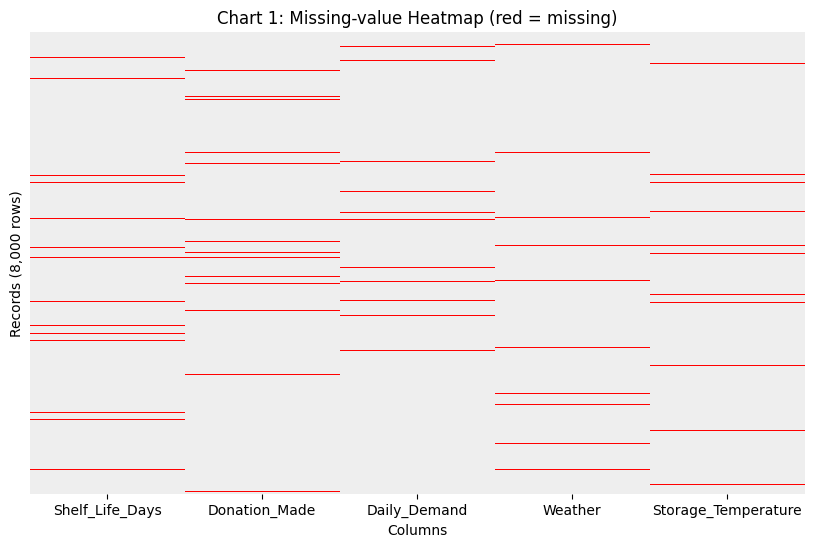

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.heatmap(df[cols_with_missing].isnull(), cbar=False, yticklabels=False, cmap=["#eeeeee", "red"])
plt.title("Chart 1: Missing-value Heatmap (red = missing)")
plt.xlabel("Columns")
plt.ylabel("Records (8,000 rows)")
plt.show()

**Observation**

Based on the heatmap above, the red line represents the missing data. This heatmap shows that the missing data is scattered all the way down and not clumped together in one area. This means that the missing values appear scattered without an obvious pattern. A few of the lines line up on the same rows, but most of them line up in different rows. This tells us that dropping rows would remove 12.6% of the data and that amount is quite large.


In [10]:
# is the missing data the same across groups?

missing_by_category = (
    df.groupby("Food_Category") [cols_with_missing]
    .apply(lambda g: g.isnull().mean() * 100)
    .round(2)
)

display(missing_by_category)

,Shelf_Life_Days,Donation_Made,Daily_Demand,Weather,Storage_Temperature
Food_Category,,,,,
Bakery,2.89,3.29,2.17,2.57,2.17
Dairy,3.10,2.32,2.15,2.84,2.50
Fruits,3.07,3.00,3.70,2.66,3.07
Meat,2.08,3.43,2.24,2.00,2.16
Prepared Food,3.31,2.70,2.16,2.43,2.23
Vegetables,3.08,2.73,3.15,2.73,1.82


**Observation**

Based on this table, we can identify that the food category with the lowest missing percentage is Vegetables with Storage_Temperature of 1.82%. Meanwhile, Fruits has the highest missing percentage with Daily_Demand of 3.70%. The percentage across categories is spread evenly the same as the heatmap, which tells us that the missing data has no clear pattern and spread randomly.

The difference between these two categories is small, with only ~1.88% gap. Since the gap is small, this means that each catogory is not missing much more data than the others. So, it is safe to fill in the gaps as no category will end up with more guessed values than others.

###Investigate each column

In [11]:
import numpy as np

# Keep an untouched copy of the original data to compare before vs after
df_raw = df.copy()

1. Shelf_Life_Days

In [12]:
print(df["Shelf_Life_Days"].describe())
print("\n--- Median Shelf_Life_Days by Food_Category ---")
print(df.groupby("Food_Category")["Shelf_Life_Days"].median())

count    7765.000000
mean        4.364585
std         2.598122
min         1.000000
25%         2.000000
50%         4.000000
75%         6.000000
max        14.000000
Name: Shelf_Life_Days, dtype: float64

--- Median Shelf_Life_Days by Food_Category ---
Food_Category
Bakery           3.0
Dairy            7.0
Fruits           5.0
Meat             4.0
Prepared Food    1.0
Vegetables       6.0
Name: Shelf_Life_Days, dtype: float64


**Observation (Shelf_Life_Days)**

The overall median shelf life is 4 days, but it differs a lot by food type: Prepared Food is 1 day, while Dairy is 7 days. Using 4 days for a missing Prepared Food row would be wrong. So, we will fill the missing values with the median of each Food_Category. We use the median because it is not affected by extreme values.

2. Storage_Temperature

In [13]:
print(df["Storage_Temperature"].describe())
print("\n--- Median Storage_Temperature by Food_Category ---")
print(df.groupby("Food_Category")["Storage_Temperature"].median())

count    7814.000000
mean       10.450064
std         8.431281
min        -4.400000
25%         3.700000
50%         7.500000
75%        18.100000
max        36.600000
Name: Storage_Temperature, dtype: float64

--- Median Storage_Temperature by Food_Category ---
Food_Category
Bakery           22.0
Dairy             3.9
Fruits            7.9
Meat              1.9
Prepared Food    19.9
Vegetables        5.9
Name: Storage_Temperature, dtype: float64


**Observation (Storage_Temperature)**

The overall median temperature is 7.5°C, but each food category is stored very differently. Meat has a median of 1.9°C (chilled), while Bakery has 22.0°C (room temperature). Filling a missing Meat temperature with 7.5°C would not make sense. This means, just like Shelf_Life_Days, we will fill the missing values using the median of each Food_Category.

3. Daily_Demand

In [14]:
print("Mean:", round(df["Daily_Demand"].mean(), 1))
print("Median:", df["Daily_Demand"].median())
print("Skew:", round(df["Daily_Demand"].skew(), 2))

print("\n--- Median Daily_Demand by Business_Type and Food_Category ---")
display(df.groupby(["Business_Type", "Food_Category"])["Daily_Demand"].median().unstack())

Mean: 105.1
Median: 94.0
Skew: 0.96

--- Median Daily_Demand by Business_Type and Food_Category ---


Food_Category,Bakery,Dairy,Fruits,Meat,Prepared Food,Vegetables
Business_Type,,,,,,
Cafeteria,62.0,63.0,61.0,59.0,62.0,61.5
Cloud Kitchen,104.0,99.0,101.0,104.0,102.0,103.0
Restaurant,81.0,82.0,82.0,83.0,78.0,83.0
Supermarket,154.0,157.0,152.0,152.5,151.0,151.0


**Observation (Daily_Demand)**

The mean (105.1) is higher than the median (94.0), and the skew is 0.96. This means a few very large values pull the mean up, so the median is safer to use. Demand also depends on the business type and food category, so we will fill the missing values with the median of each Business_Type and Food_Category group. Since demand cannot be lower than units sold, any filled value below Units_Sold will be raised to match it.

4. Donation_Made

In [15]:
print(pd.crosstab(df["Donation_Made"].fillna("MISSING"),
                  np.where(df["Waste_Quantity"] > 0, "Waste > 0", "Waste = 0")))

col_0          Waste = 0  Waste > 0
Donation_Made                      
MISSING               96        137
No                  3319       3392
Yes                    0       1056


**Observation (Donation_Made)**

The table shows that when Waste_Quantity is 0, Donation_Made is never "Yes" (0 rows). This makes sense because if there is no waste, there is nothing to donate. So, for the 96 missing rows with no waste, the answer must be "No", and we can fill them with certainty. For the other 137 missing rows, there was waste, so we cannot know whether food was donated or not. Instead of guessing, we will label them as "Unknown".

5. Weather

In [16]:
print(df["Weather"].value_counts(dropna=False))

Weather
Sunny     2693
Cloudy    1931
Hot       1605
Rainy     1568
NaN        203
Name: count, dtype: int64


**Observation (Weather)**

Sunny is the most common weather (2,693 rows). If we filled all 203 missing values with "Sunny", it would make sunny days look more common than they really are. Weather also cannot be worked out from any other column in the dataset. This means guessing is not reliable, so we will flag the missing values as a new category, "Unknown".

###Flag before Filling

In [17]:
for col in cols_with_missing:
    df[col + "_was_missing"] = df[col].isnull().astype(int)

print("Flag columns added:")
print([c for c in df.columns if c.endswith("_was_missing")])

Flag columns added:
['Shelf_Life_Days_was_missing', 'Donation_Made_was_missing', 'Daily_Demand_was_missing', 'Weather_was_missing', 'Storage_Temperature_was_missing']


Before filling in the gaps, we added a flag column for each column with missing values, named `<column>_was_missing`. It shows 1 if the value was missing and 0 if it was there from the start.

This helps us remember which values we filled in ourselves, so we can leave them out later if needed. We did this first because once the gaps are filled, we cannot tell which values were missing anymore.

In [18]:
# 1) Shelf_Life_Days -> median of each Food_Category
df["Shelf_Life_Days"] = df["Shelf_Life_Days"].fillna(
    df.groupby("Food_Category")["Shelf_Life_Days"].transform("median"))

# 2) Storage_Temperature -> median of each Food_Category
df["Storage_Temperature"] = df["Storage_Temperature"].fillna(
    df.groupby("Food_Category")["Storage_Temperature"].transform("median"))

# 3) Daily_Demand -> median of each Business_Type + Food_Category group
df["Daily_Demand"] = df["Daily_Demand"].fillna(
    df.groupby(["Business_Type", "Food_Category"])["Daily_Demand"].transform("median"))
# Demand cannot be lower than units sold
df["Daily_Demand"] = np.maximum(df["Daily_Demand"], df["Units_Sold"])

# 4) Donation_Made -> "No" when there was no waste, "Unknown" for the rest
no_waste_mask = df["Donation_Made"].isnull() & (df["Waste_Quantity"] == 0)
df.loc[no_waste_mask, "Donation_Made"] = "No"
print("Donation_Made filled with 'No' (no waste):", no_waste_mask.sum())
df["Donation_Made"] = df["Donation_Made"].fillna("Unknown")

# 5) Weather -> flag as "Unknown"
df["Weather"] = df["Weather"].fillna("Unknown")

Donation_Made filled with 'No' (no waste): 96


In [19]:
print("--- Missing values after handling ---")
print(df[cols_with_missing].isnull().sum())

print("\n--- Median before vs after ---")
num_cols = ["Shelf_Life_Days", "Storage_Temperature", "Daily_Demand"]
display(pd.DataFrame({"Before": df_raw[num_cols].median(),
                      "After": df[num_cols].median()}))

print("Rows where Daily_Demand < Units_Sold:", (df["Daily_Demand"] < df["Units_Sold"]).sum())

print("\n", df["Weather"].value_counts())
print("\n", df["Donation_Made"].value_counts())

--- Missing values after handling ---
Shelf_Life_Days        0
Donation_Made          0
Daily_Demand           0
Weather                0
Storage_Temperature    0
dtype: int64

--- Median before vs after ---


,Before,After
Shelf_Life_Days,4.0,4.0
Storage_Temperature,7.5,7.5
Daily_Demand,94.0,95.0


Rows where Daily_Demand < Units_Sold: 0

 Weather
Sunny      2693
Cloudy     1931
Hot        1605
Rainy      1568
Unknown     203
Name: count, dtype: int64

 Donation_Made
No         6807
Yes        1056
Unknown     137
Name: count, dtype: int64


**Observation**

All the missing values are now filled in. The medians before and after are almost the same (Shelf_Life_Days 4.0 → 4.0, Storage_Temperature 7.5 → 7.5, Daily_Demand 94.0 → 95.0), so filling in the gaps did not really change the data. We also checked that no Daily_Demand value is lower than Units_Sold. The only values left that we do not know are 203 "Unknown" in Weather and 137 "Unknown" in Donation_Made, and they are clearly labelled.

**Summary**

| Column | Missing | What we did | Why |
|---|---|---|---|
| Shelf_Life_Days | 235 (2.94%) | Filled with the median of each food category | Each food type lasts a different number of days |
| Storage_Temperature | 186 (2.33%) | Filled with the median of each food category | Each food type is stored at a different temperature |
| Daily_Demand | 210 (2.62%) | Filled with the median of each business type + food category, and made sure it's not lower than Units_Sold | A few very high values pull the average up; demand can't be lower than what was sold |
| Donation_Made | 233 (2.91%) | Filled "No" when there was no waste (96 rows); "Unknown" for the rest (137 rows) | No waste means nothing to donate; for the others we can't know, so we did not guess |
| Weather | 203 (2.54%) | Labelled as "Unknown" | We can't work out the weather from other columns, and filling with "Sunny" would make it look more common than it is |
| All 5 columns | – | Added `_was_missing` flag columns | So we know which values we filled in ourselves |

**Why were no rows dropped?:**

Removing every row with a missing value would mean losing 1,006 rows (12.6% of the data). The missing values are random and spread evenly across food categories, so filling them in was the better choice.

## 3. (b) Outliers

In this step, we check for outliers across all 7 numerical columns

    - Purchase_Quantity
    - Units_Sold
    - Remaining_Stock
    - Shelf_Life_Days
    - Storage_Temperature
    - Daily_Demand
    - Waste_Quantity

We use two standard methods to detect outliers:
1. **IQR Method:**
    - Values outside the range of `Q1 - 1.5 * IQR` and `Q3 + 1.5 * IQR`.
2. **Z-Score Method:**
    - Extreme values where the Z-score is greater than 3 or less than -3 (more than 3 standard deviations away from the mean).

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Select all 7 numerical columns
num_cols = ['Purchase_Quantity', 'Units_Sold', 'Remaining_Stock',
            'Shelf_Life_Days', 'Storage_Temperature', 'Daily_Demand', 'Waste_Quantity']

# Calculate IQR and Z-Score outliers
outlier_data = []

for col in num_cols:
    s = df[col]
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    iqr_count = len(s[(s < lower_bound) | (s > upper_bound)])
    z_count = len(s[np.abs(stats.zscore(s)) > 3])

    outlier_data.append({
        'Column': col,
        'Min': round(s.min(), 1),
        'Max': round(s.max(), 1),
        'Q1': round(q1, 1),
        'Q3': round(q3, 1),
        'IQR': round(iqr, 1),
        'Upper Limit (Q3 + 1.5*IQR)': round(upper_bound, 1),
        'IQR Outliers Count (%)': f"{iqr_count} ({round(iqr_count/len(s)*100, 2)}%)",
        'Z-Score Outliers Count (%)': f"{z_count} ({round(z_count/len(s)*100, 2)}%)"
    })

df_outliers = pd.DataFrame(outlier_data)
print("----- OUTLIER SUMMARY TABLE -----")
display(df_outliers)

----- OUTLIER SUMMARY TABLE -----


,Column,Min,Max,Q1,Q3,IQR,Upper Limit (Q3 + 1.5*IQR),IQR Outliers Count (%),Z-Score Outliers Count (%)
0,Purchase_Quantity,35.0,968.0,80.0,148.0,68.0,250.0,100 (1.25%),54 (0.68%)
1,Units_Sold,26.0,284.0,67.0,121.0,54.0,202.0,88 (1.1%),50 (0.62%)
2,Remaining_Stock,0.0,858.0,0.0,30.0,30.0,75.0,357 (4.46%),75 (0.94%)
3,Shelf_Life_Days,1.0,14.0,2.0,6.0,4.0,12.0,42 (0.53%),42 (0.53%)
4,Storage_Temperature,-4.4,36.6,3.7,18.2,14.5,40.0,0 (0.0%),2 (0.03%)
5,Daily_Demand,26.0,316.0,71.0,133.0,62.0,226.0,123 (1.54%),62 (0.78%)
6,Waste_Quantity,0.0,447.0,0.0,7.0,7.0,17.5,550 (6.88%),68 (0.85%)


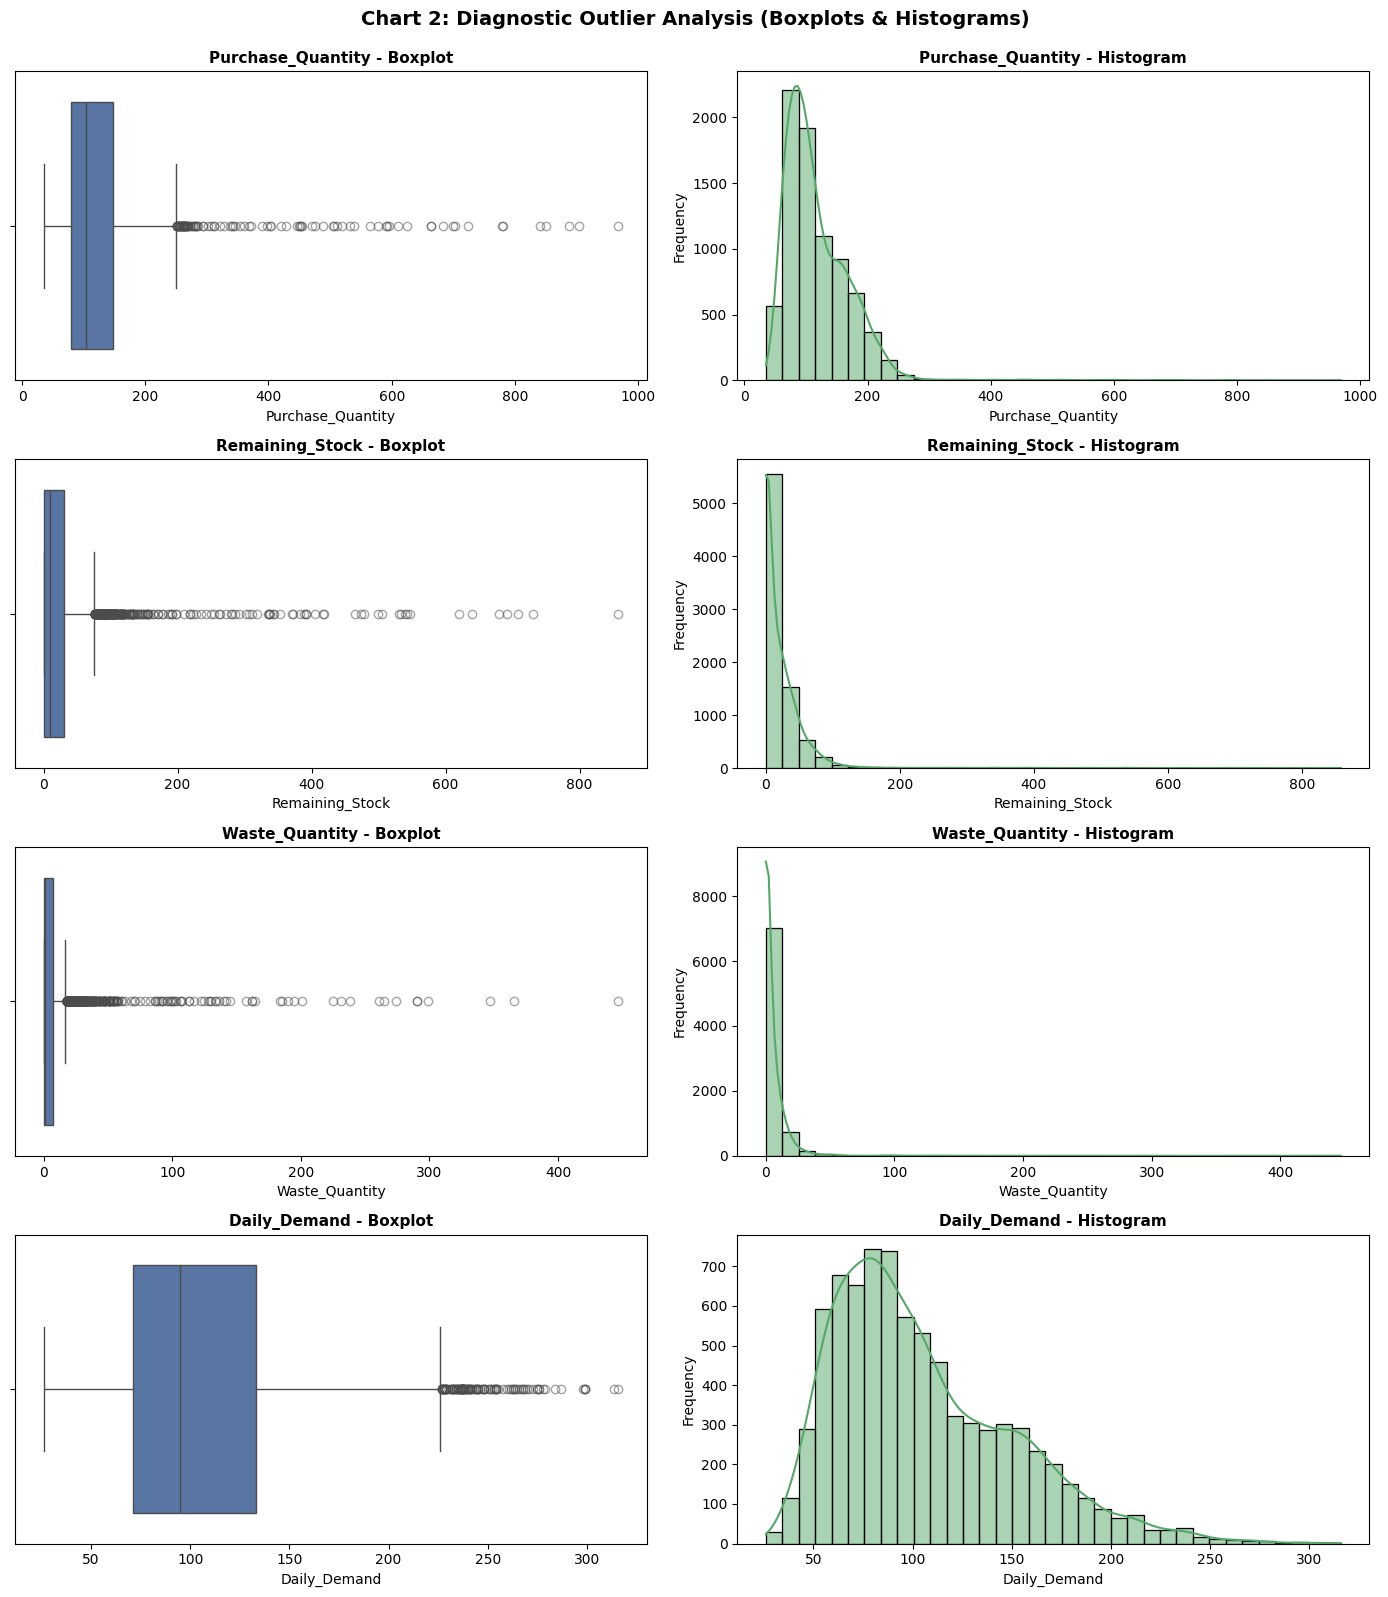

In [21]:
# Chart 2: Boxplots and Histograms for Outlier Analysis
fig, axes = plt.subplots(4, 2, figsize=(14, 16))
fig.suptitle('Chart 2: Diagnostic Outlier Analysis (Boxplots & Histograms)', fontsize=14, fontweight='bold', y=0.995)

plot_cols = ['Purchase_Quantity', 'Remaining_Stock', 'Waste_Quantity', 'Daily_Demand']

for idx, col in enumerate(plot_cols):
    # Left plot: Boxplot
    sns.boxplot(data=df, x=col, ax=axes[idx, 0], color='#4C72B0', flierprops=dict(marker='o', color='red', alpha=0.5))
    axes[idx, 0].set_title(f'{col} - Boxplot', fontsize=11, fontweight='bold')
    axes[idx, 0].set_xlabel(col)

    # Right plot: Histogram
    sns.histplot(data=df, x=col, ax=axes[idx, 1], kde=True, bins=35, color='#55A868')
    axes[idx, 1].set_title(f'{col} - Histogram', fontsize=11, fontweight='bold')
    axes[idx, 1].set_xlabel(col)
    axes[idx, 1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

### Outlier Summary & Decisions

| Column | Min | Max | Q1 | Q3 | IQR | Upper Limit (Q3 + 1.5 * IQR) | IQR Outliers Count (%) | Z-Score Outliers Count (%) |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **Purchase_Quantity** | 35.0 | 968.0 | 80.0 | 148.0 | 68.0 | 250.0 | 100 (1.25%) | 54 (0.68%) |
| **Units_Sold** | 26.0 | 284.0 | 67.0 | 121.0 | 54.0 | 202.0 | 88 (1.10%) | 50 (0.62%) |
| **Remaining_Stock** | 0.0 | 858.0 | 0.0 | 30.0 | 30.0 | 75.0 | 357 (4.46%) | 75 (0.94%) |
| **Daily_Demand** | 26.0 | 316.0 | 71.0 | 133.0 | 62.0 | 226.0 | 123 (1.54%) | 62 (0.78%) |
| **Waste_Quantity** | 0.0 | 447.0 | 0.0 | 7.0 | 7.0 | 17.5 | 550 (6.88%) | 68 (0.85%) |
| **Shelf_Life_Days** | 1.0 | 14.0 | 2.0 | 6.0 | 4.0 | 12.0 | 42 (0.53%) | 42 (0.53%) |
| **Storage_Temperature** | -4.4 | 36.6 | 3.7 | 18.2 | 14.5 | 40.0 | 0 (0.00%) | 2 (0.03%) |

### Outlier Handling Decisions & Reasons

We decided to keep all the outliers in the dataset. Below are the decisions + reasons for each column:

###1. **Purchase_Quantity (Max: 968 units)**

    - Keep this metric
    - High number of purchase are expected when big stores (like supermarket) stock up before peak days like weekends.
    - Remaining_Stock is calculated using formula:

          Remaining_Stock = Purchase_Quantity - Units_Sold
    
    - If we remove/cap the Purchase_Quantity, calculation for Remaining_Stock will be messed up.


###2. **Units_Sold (Max: 284 units)**

    - Keep this metric
    - High sales happen during promotion days or rush hours.
    - So these are real sales records, not data entry error.


###3. **Remaining_Stock (Max: 858 units)**

    - Keep this metric
    - Remaining_Stock comes from formula:

          Remaining_Stock = Purchase_Quantity - Units_Sold
    
    - High remaining stock happens due to over-ordering, which is important to keep for future analysis.


###4. **Daily_Demand (Max: 316 units)**

    - Keep this metric
    - Sudden & very high increase (spike) actually happen due to customer behaviour during sales events like discounts, promotions, good weahter.


###5. **Waste_Quantity (Max: 447 units)**

    - Keep this metric
    - Food waste is the primary focus in our assignment.
    - Removing this metric would remove the most important problem cases.
    - High waste numbers also happen when the food has expired, or when the store has overproduced.


###6. **Shelf_Life_Days (Max: 14 days)**

    - Keep this metric
    - A shelf life that lasts up to 14 days is completely normal when the products/items are long-lasting like packaged bakery, canned foods, processed dairy


###7. **Storage_Temperature (Range: -4.4°C to 36.6°C)**

    - Keep this metric, flag it with high values
    - Temperatures are vary depending on the storage type (like freezer and fridge).
    - High reading in Fresh Foods help explain why the food went bad.
    - The outliers shows real storage failure, not broken sensors.

## 3. (c) Other Quality Issues

After the missing values and outliers, we check for other quality issues that can still make the data unreliable. We check 4 things:

1. **Duplicates** - the same record saved more than once, or the same ID used twice.
2. **Inconsistent formats** - extra spaces, mixed upper/lower case, different date or ID formats.
3. **Wrong data types** - columns stored as the wrong data type (e.g. dates stored as text)
4. **Invalid values** - values that break the rules of the dataset (e.g. Units_Sold higher than Purchase_Quantity)

All checks below are done on `df`, which already has the missing values handled in section 3(a). For each issue we first check it, then decide what to do and explain why.

### 1. Duplicates

In [22]:
# exact duplicate rows and duplicate IDs
print("Fully duplicated rows:", df.duplicated().sum())
print("Duplicated Inventory_ID:", df["Inventory_ID"].duplicated().sum())

# same record but with a different ID? (ignore Inventory_ID and the flag columns we added)
check_cols = [c for c in df_raw.columns if c != "Inventory_ID"]
print("Duplicated rows if we ignore Inventory_ID:", df.duplicated(subset=check_cols).sum())

Fully duplicated rows: 0
Duplicated Inventory_ID: 0
Duplicated rows if we ignore Inventory_ID: 0


In [23]:
# rows with the same Date + Business_Type + Food_Category
key = ["Date", "Business_Type", "Food_Category"]
print("Rows sharing the same Date + Business_Type + Food_Category with another row:", df.duplicated(subset=key, keep=False).sum())

# do they also have the same quantities?
qty_key = key + ["Purchase_Quantity", "Units_Sold", "Waste_Quantity"]
same_qty = df.duplicated(subset=qty_key, keep=False)
print("Rows that also have the same Purchase_Quantity, Units_Sold and Waste_Quantity:", same_qty.sum())

display(df[same_qty].sort_values(key)[key + ["Purchase_Quantity", "Units_Sold", "Waste_Quantity",
                                              "Shelf_Life_Days", "Storage_Temperature", "Daily_Demand"]].head(6))

Rows sharing the same Date + Business_Type + Food_Category with another row: 4939
Rows that also have the same Purchase_Quantity, Units_Sold and Waste_Quantity: 18


,Date,Business_Type,Food_Category,Purchase_Quantity,Units_Sold,Waste_Quantity,Shelf_Life_Days,Storage_Temperature,Daily_Demand
398,2025-01-18,Supermarket,Bakery,167,167,0,2.0,25.6,184.0
407,2025-01-18,Supermarket,Bakery,167,167,0,5.0,22.5,173.0
608,2025-01-28,Cafeteria,Prepared Food,53,53,0,1.0,9.0,68.0
609,2025-01-28,Cafeteria,Prepared Food,53,53,0,1.0,21.9,71.0
669,2025-01-31,Cafeteria,Dairy,44,44,0,10.0,3.3,51.0
689,2025-01-31,Cafeteria,Dairy,44,44,0,7.0,4.6,50.0


**Observation (Duplicates)**

There are no fully duplicated rows and no repeated Inventory_ID. Even when we ignore Inventory_ID, there are still 0 duplicated rows. This means the same record was not saved twice under different ID.

We also checked rows that share the same Date, Business_Type and Food_Category. There are 4,939 of them, but this is expected because the dataset has no outlet or branch column, so many outlets of the same business type can sell the same food category on the same day. Only 18 rows (9 pairs) also have the same Purchace_Quantity, Units_Sold and Waste_Quantity. Since there are 0 duplicates when we ignore Inventory_ID, these pairs must be different in at least one other column (for example Storage_Temperature and Daily_Demand in the table above), so they are not copies of each other. We decided to keep all rows.

### 2. Inconsistent Formats

In [24]:
text_cols = ["Inventory_ID", "Business_Type", "Food_Category", "Promotion",
             "Weather", "Waste_Reason", "Donation_Made", "Waste_Level"]

format_check = []
for col in text_cols:
    s = df[col].astype(str)
    format_check.append({
        "Column": col,
        "Unique Values": s.nunique(),
        "Extra Spaces": int((s != s.str.strip()).sum()),
        "Upper/Lower Case Variants": int(s.nunique() - s.str.strip().str.lower().nunique())
    })

display(pd.DataFrame(format_check))

,Column,Unique Values,Extra Spaces,Upper/Lower Case Variants
0,Inventory_ID,8000,0,0
1,Business_Type,4,0,0
2,Food_Category,6,0,0
3,Promotion,2,0,0
4,Weather,5,0,0
5,Waste_Reason,5,0,0
6,Donation_Made,3,0,0
7,Waste_Level,3,0,0


In [25]:
# date, ID and decimal formats
print("Date not in YYYY-MM-DD format:", (~df["Date"].astype(str).str.match(r"^\d{4}-\d{2}-\d{2}$")).sum())
print("Inventory_ID not in INV + 6 digits format:", (~df["Inventory_ID"].astype(str).str.match(r"^INV\d{6}$")).sum())

temp_x10 = df["Storage_Temperature"] * 10
print("Storage_Temperature with more than 1 decimal place:", (~np.isclose(temp_x10, temp_x10.round())).sum())

# the labels inside each category column
for col in ["Business_Type", "Food_Category", "Promotion", "Weather", "Waste_Reason", "Donation_Made", "Waste_Level"]:
    print(f"{col}: {sorted(df[col].unique())}")

Date not in YYYY-MM-DD format: 0
Inventory_ID not in INV + 6 digits format: 0
Storage_Temperature with more than 1 decimal place: 0
Business_Type: ['Cafeteria', 'Cloud Kitchen', 'Restaurant', 'Supermarket']
Food_Category: ['Bakery', 'Dairy', 'Fruits', 'Meat', 'Prepared Food', 'Vegetables']
Promotion: ['No', 'Yes']
Weather: ['Cloudy', 'Hot', 'Rainy', 'Sunny', 'Unknown']
Waste_Reason: ['Expired', 'Low Demand', 'No Waste', 'Overproduction', 'Storage Issue']
Donation_Made: ['No', 'Unknown', 'Yes']
Waste_Level: ['High', 'Low', 'Medium']


**Observation (Formats)**

All the text columns are consistent. There are no extra spaces and no upper/lower case problems (for example "sunny" and "Sunny" counted as 2 different values). Every column only has the labels written in the data dictionary. The only extra labels are the "Unknown" in Weather and Donation_Made, which we added ourselves in section 3 (a) on purpose.

The Date column is always in YYYY-MM-DD format, every Inventory_ID follows the INV + 6 digits pattern, and Storage_Temperature never has more than 1 decimal place. So nothing needed to be fixed there. We still run a `.str.strip()` step below as a safety step, and it changes 0 values.

In [26]:
# safety step: remove any extra spaces (this changes 0 values, but keeps the columns clean)
for col in text_cols:
    df[col] = df[col].astype(str).str.strip()

### 3. Wrong Data Types

In [27]:
def show_types(d):
    # older pandas shows text columns as 'object', newer pandas shows 'str' (same thing for us)
    t = d[df_raw.columns].dtypes.astype(str)
    return t.str.replace(r"\[.*\]", "", regex=True).replace({"str": "object"})

should_be = {
    "Inventory_ID": "text (ID)", "Date": "datetime", "Business_Type": "category",
    "Food_Category": "category", "Purchase_Quantity": "integer", "Units_Sold": "integer",
    "Remaining_Stock": "integer", "Shelf_Life_Days": "integer", "Storage_Temperature": "float",
    "Daily_Demand": "integer", "Promotion": "category", "Weather": "category",
    "Waste_Quantity": "integer", "Waste_Reason": "category", "Donation_Made": "category",
    "Waste_Level": "category (ordered)"
}

type_table = pd.DataFrame({
    "Current Type": show_types(df),
    "Should Be": pd.Series(should_be)
})
display(type_table)

,Current Type,Should Be
Inventory_ID,object,text (ID)
Date,object,datetime
Business_Type,object,category
Food_Category,object,category
Purchase_Quantity,int64,integer
Units_Sold,int64,integer
Remaining_Stock,int64,integer
Shelf_Life_Days,float64,integer
Storage_Temperature,float64,float
Daily_Demand,float64,integer


Data is stored as text, so we cannot use it to get the month or day of the week. Shelf_Life_Days and Daily_Demand are float, but the data dictionary says they are integer-valued (they only become float because of the missing values). The column with a few fixed labels are better as category.

In [28]:
# Shelf_Life_Days and Daily_Demand should be whole numbers (units / days)
for col in ["Shelf_Life_Days", "Daily_Demand"]:
    print(col, "- values that are not whole numbers:", (df[col] % 1 != 0).sum())

display(df.loc[df["Daily_Demand"] % 1 != 0,
               ["Business_Type", "Food_Category", "Units_Sold", "Daily_Demand", "Daily_Demand_was_missing"]])

Shelf_Life_Days - values that are not whole numbers: 0
Daily_Demand - values that are not whole numbers: 11


,Business_Type,Food_Category,Units_Sold,Daily_Demand,Daily_Demand_was_missing
93,Cafeteria,Vegetables,55,61.5,1
798,Cafeteria,Vegetables,52,61.5,1
827,Cafeteria,Vegetables,43,61.5,1
4635,Supermarket,Meat,140,152.5,1
5022,Supermarket,Meat,92,152.5,1
5156,Cafeteria,Vegetables,56,61.5,1
5403,Supermarket,Meat,128,152.5,1
5513,Cafeteria,Vegetables,59,61.5,1
5630,Supermarket,Meat,88,152.5,1
7075,Cafeteria,Vegetables,61,61.5,1


**Observation (Daily_Demand)**

This problem came from our own filling step in section 3 (a). 11 Daily_Demand values are not whole numbers (61.5 and 152.5). It happened because the median of a group with an even number of rows can end with .5. Demand is counted in units, so a half unit does not make sense.

We round these up (not down) so that Daily_Demand is still not lower than Units_Sold, which is the same rule we used when filling the missing values. Only 11 rows (0.14%) are affected, so the effect on the data is very small.

In [29]:
# Daily_Demand: round UP to a whole number (so it is still not lower than Units_Sold)
df["Daily_Demand"] = np.ceil(df["Daily_Demand"])

# Date: text -> datetime
df["Date"] = pd.to_datetime(df["Date"], format="%Y-%m-%d", errors="coerce")
print("Dates that could not be converted:", df["Date"].isnull().sum())

# whole-number columns: float -> int (there are no missing values left, so this is safe)
for col in ["Shelf_Life_Days", "Daily_Demand"]:
    df[col] = df[col].astype(int)

# text columns with a few fixed labels: text -> category
cat_cols = ["Business_Type", "Food_Category", "Promotion", "Weather", "Waste_Reason", "Donation_Made"]
for col in cat_cols:
    df[col] = df[col].astype("category")

# Waste_Level has a natural order, so we make it an ordered category
df["Waste_Level"] = pd.Categorical(df["Waste_Level"], categories=["Low", "Medium", "High"], ordered=True)

print("\nDaily_Demand below Units_Sold:", (df["Daily_Demand"] < df["Units_Sold"]).sum())
display(show_types(df).to_frame("Type After Fix"))

Dates that could not be converted: 0

Daily_Demand below Units_Sold: 0


,Type After Fix
Inventory_ID,object
Date,datetime64
Business_Type,category
Food_Category,category
Purchase_Quantity,int64
Units_Sold,int64
Remaining_Stock,int64
Shelf_Life_Days,int64
Storage_Temperature,float64
Daily_Demand,int64


**Observation (Data types)**

Date is now datetime, the two whole-number columns are now integer, and the text columns with fixed labels are now category. Waste_Level is an ordered category (Low < Medium < High) because it has a natural order. Inventory_ID stays as text because it is only an ID and we do not calculate with it. After the changes, no Daily_Demand is lower than Units_Sold.

### 4. Invalid Values

We test 12 rules that come from the data dictionary and basic common sense (for example, units sold cannot be more than units purchased, and waste cannot be more than the stock left). A row that breaks a rule is an invalid row.

In [30]:
qty_cols = ["Purchase_Quantity", "Units_Sold", "Remaining_Stock", "Daily_Demand", "Waste_Quantity"]

def check_rules(d):
    # each rule gives True for the rows that break it
    rules = {
        "Negative value in any quantity column": (d[qty_cols] < 0).any(axis=1),
        "Shelf_Life_Days less than 1": d["Shelf_Life_Days"] < 1,
        "Units_Sold more than Purchase_Quantity": d["Units_Sold"] > d["Purchase_Quantity"],
        "Remaining_Stock is not Purchase_Quantity - Units_Sold": d["Remaining_Stock"] != d["Purchase_Quantity"] - d["Units_Sold"],
        "Waste_Quantity more than Remaining_Stock": d["Waste_Quantity"] > d["Remaining_Stock"],
        "Daily_Demand less than Units_Sold": d["Daily_Demand"] < d["Units_Sold"],
        "Waste_Reason is 'No Waste' but Waste_Quantity > 0": (d["Waste_Reason"] == "No Waste") & (d["Waste_Quantity"] > 0),
        "Waste_Reason is not 'No Waste' but Waste_Quantity = 0": (d["Waste_Reason"] != "No Waste") & (d["Waste_Quantity"] == 0),
        "Donation_Made is 'Yes' but Waste_Quantity = 0": (d["Donation_Made"] == "Yes") & (d["Waste_Quantity"] == 0),
        "Donation_Made is 'Yes' but Waste_Reason is 'Expired'": (d["Donation_Made"] == "Yes") & (d["Waste_Reason"] == "Expired"),
        "Date outside 2025": (d["Date"] < "2025-01-01") | (d["Date"] > "2025-12-31"),
        "Waste_Level is not 'Low' but Waste_Quantity = 0": (d["Waste_Quantity"] == 0) & (d["Waste_Level"] != "Low"),
    }
    return pd.Series({name: int(mask.sum()) for name, mask in rules.items()})

rules_before = check_rules(df)

invalid_table = pd.DataFrame({"Rows Failing": rules_before})
invalid_table["Percentage"] = (invalid_table["Rows Failing"] / len(df) * 100).round(2)
display(invalid_table)

,Rows Failing,Percentage
Negative value in any quantity column,0,0.0
Shelf_Life_Days less than 1,0,0.0
Units_Sold more than Purchase_Quantity,0,0.0
Remaining_Stock is not Purchase_Quantity - Units_Sold,0,0.0
Waste_Quantity more than Remaining_Stock,0,0.0
Daily_Demand less than Units_Sold,0,0.0
Waste_Reason is 'No Waste' but Waste_Quantity > 0,0,0.0
Waste_Reason is not 'No Waste' but Waste_Quantity = 0,0,0.0
Donation_Made is 'Yes' but Waste_Quantity = 0,0,0.0
Donation_Made is 'Yes' but Waste_Reason is 'Expired',0,0.0


**Observation**

11 out of 12 rules have 0 failing rows. This means the quantity columns are consistent with each other (Remaining_Stock always equals Purchase_Quantity - Units_Sold, waste is never more than the stock left, and no one donated food when there was no waste or when the food was expired). Only 1 rule failed: **Waste_Level** with 104 rows (1.3%). We look at it closer below.

In [31]:
# look closer at the Waste_Level problem
bad_level = (df["Waste_Quantity"] == 0) & (df["Waste_Level"] != "Low")

print("Waste_Level of the rows where Waste_Quantity = 0:")
print(df.loc[df["Waste_Quantity"] == 0, "Waste_Level"].value_counts())

print("\nWaste_Reason of the", bad_level.sum(), "problem rows:")
print(df.loc[bad_level, "Waste_Reason"].value_counts())

# waste-to-purchase ratio range of each level (rows with waste only)
ratio = df["Waste_Quantity"] / df["Purchase_Quantity"]
print("\nWaste-to-purchase ratio by Waste_Level (rows with waste only):")
display(ratio[df["Waste_Quantity"] > 0].groupby(df["Waste_Level"], observed=True).agg(["min", "median", "max"]).round(3))

Waste_Level of the rows where Waste_Quantity = 0:
Waste_Level
Low       3311
High        54
Medium      50
Name: count, dtype: int64

Waste_Reason of the 104 problem rows:
Waste_Reason
No Waste          104
Expired             0
Low Demand          0
Overproduction      0
Storage Issue       0
Name: count, dtype: int64

Waste-to-purchase ratio by Waste_Level (rows with waste only):


,min,median,max
Waste_Level,,,
Low,0.003,0.013,0.251
Medium,0.005,0.048,0.307
High,0.006,0.122,0.494


**Observation (Waste_Level)**

The data dictionary says Waste_Level is made from the waste-to-purchase ratio. When Waste_Quantity is 0 the ratio is also 0, so the level should always be "Low". But 54 of these rows are "High" and 50 are "Medium". All 104 rows have Waste_Reason = "No Waste", so Waste_Quantity and Waste_Reason agree with each other, and Waste_Level is the odd one out.

So we change these 104 rows to "Low" and add a `Waste_Level_was_corrected` flag, the same way we did with the `_was_missing` flags. We did not drop the rows because only 1 column is wrong and the rest of the row is fine, and we did not change Waste_Quantity because two columns already agree that there was no waste.

The ratio table also shows that the levels overlap a bit among the rows with waste (for example, the highest ratio in "Low" is 0.251, which is higher than the median of "High" at 0.122). The data dictionary does not give the cut-off values, so we cannot tell which of these labels are wrong. We leave them as they are and mention it as a limitation for the conclusion.

In [32]:
# flag first, then fix (same idea as the _was_missing flags)
df["Waste_Level_was_corrected"] = bad_level.astype(int)
df.loc[bad_level, "Waste_Level"] = "Low"

print("Rows corrected:", df["Waste_Level_was_corrected"].sum())
print("Waste_Level when Waste_Quantity = 0 (after fix):")
print(df.loc[df["Waste_Quantity"] == 0, "Waste_Level"].value_counts())

print("\nWaste_Level before vs after:")
display(pd.DataFrame({"Before": df_raw["Waste_Level"].value_counts(),
                      "After": df["Waste_Level"].value_counts()}))

Rows corrected: 104
Waste_Level when Waste_Quantity = 0 (after fix):
Waste_Level
Low       3415
Medium       0
High         0
Name: count, dtype: int64

Waste_Level before vs after:


,Before,After
Waste_Level,,
Low,4331,4435
Medium,2397,2347
High,1272,1218


**Observation**

After the fix, every row with no waste is "Low", so the problem is gone. The "Low" group grew from 4,331 to 4,435 rows, while "Medium" went down by 50 and "High" went down by 54. The numbers are still close to the original, so the fix did not change the overall picture.

**Storage_Temperature**

In section 3 (b) we kept the temperature outliers because they can show real storage problems. But there is still one more thing to check: some foods should never be stored below 0°C.

In [33]:
# negative storage temperature by food category
print("Rows with Storage_Temperature below 0:", (df["Storage_Temperature"] < 0).sum())
print(df.loc[df["Storage_Temperature"] < 0, "Food_Category"].value_counts())

# flag chilled (not frozen) foods stored below 0 degrees
not_frozen = ["Dairy", "Fruits", "Vegetables"]
df["Storage_Temperature_suspect"] = (df["Food_Category"].isin(not_frozen) & (df["Storage_Temperature"] < 0)).astype(int)
print("\nRows flagged as suspect:", df["Storage_Temperature_suspect"].sum())

Rows with Storage_Temperature below 0: 270
Food_Category
Meat             200
Vegetables        37
Dairy             28
Fruits             5
Bakery             0
Prepared Food      0
Name: count, dtype: int64

Rows flagged as suspect: 70


**Observation (Storage_Temperature)**

270 rows are below 0°C. 200 of them are Meat, and this is fine because meat can be stored frozen. But the other 70 rows are Dairy (28), Vegetables (37) and Fruits (5). These foods are normally kept in a fridge above freezing, and below 0°C they can freeze and get spoiled. We cannot know whether these are sensor mistakes or real storage failures.

So we keep the values and only add a `Storage_Temperature_suspect` flag. This is the same decision as our outlier handling in section 3 (b). We do not remove them because they are only 70 rows (0.9%) and we cannot prove they are wrong. With the flag, we can leave them out later if needed.

### Final check after the fixes

In [34]:
# final check: run all the rules again after the fixes
rules_after = check_rules(df)

display(pd.DataFrame({"Rows Failing Before": rules_before, "Rows Failing After": rules_after}))
print("Final shape:", df.shape)

,Rows Failing Before,Rows Failing After
Negative value in any quantity column,0,0
Shelf_Life_Days less than 1,0,0
Units_Sold more than Purchase_Quantity,0,0
Remaining_Stock is not Purchase_Quantity - Units_Sold,0,0
Waste_Quantity more than Remaining_Stock,0,0
Daily_Demand less than Units_Sold,0,0
Waste_Reason is 'No Waste' but Waste_Quantity > 0,0,0
Waste_Reason is not 'No Waste' but Waste_Quantity = 0,0,0
Donation_Made is 'Yes' but Waste_Quantity = 0,0,0
Donation_Made is 'Yes' but Waste_Reason is 'Expired',0,0


Final shape: (8000, 23)


**Summary**

| Issue | What we found | What we did | Why |
|---|---|---|---|
| Duplicates | 0 duplicated rows, 0 repeated IDs. 18 rows (9 pairs) share the same Date, Business_Type, Food_Category and quantities | Kept all rows | The pairs are different in other columns, and there is no outlet column so the same group on the same day is normal |
| Inconsistent formats | None. No extra spaces, no case problems, Date and ID formats are all the same | Added a safety `.str.strip()` (0 values changed) | Nothing needed to be fixed, but this keeps the text columns clean |
| Wrong data types | Date stored as text, 2 whole-number columns stored as float, text labels stored as object, 11 Daily_Demand values like 61.5 | Date to datetime, whole numbers to int, labels to category (Waste_Level ordered). 11 Daily_Demand values rounded up | The types now match the data dictionary, and a half unit of demand does not make sense |
| Invalid values | 104 rows (1.3%) with Waste_Quantity = 0 but Waste_Level Medium/High | Changed to "Low" and added `Waste_Level_was_corrected` flag | Ratio is 0 so the level must be Low, and Waste_Reason also says "No Waste" |
| Suspect values | 70 rows of Dairy/Vegetables/Fruits stored below 0°C | Kept, added `Storage_Temperature_suspect` flag | We cannot prove they are mistakes, and they may be real storage failures |

**Why were no rows dropped?:**

In this step all the problems were in 1 column of a row, and the rest of each row is still correct. Dropping rows would waste good data, so we fixed the wrong value or added a flag instead. The 2 new flag columns (`Waste_Level_was_corrected` and `Storage_Temperature_suspect`) let us see or remove the changed rows later if we need to.

## 5. PII and Bias Risks

In this section we check 2 things. First, whether the data has any personally identifiable information (PII) that could point to a real person or business. Second, whether the data has sampling bias or unbalanced groups that could make the results unfair or misleading. We only find and explain the risks here, so we do not change or remove anything in the dataset.

### 5 (a) PII Risk

In [35]:
pii_keywords = ["name", "phone", "email", "address", "nric", "ic", "passport",
                "gps", "lat", "lon", "location", "customer", "staff", "employee", "account", "card"]

found = [c for c in df_raw.columns if any(k in c.lower().split("_") for k in pii_keywords)]
print("Columns that look like direct PII:", found if found else "None")

# could a combination of fields point to one record? (quasi-identifier check)
qi = ["Date", "Business_Type", "Food_Category"]
group_size = df.groupby(qi, observed=True)["Inventory_ID"].transform("count")
print("\nGroup size of Date + Business_Type + Food_Category:")
print("Smallest group:", group_size.min())
print("Median group size:", int(group_size.median()))
print("Rows that are unique on these 3 fields:", (group_size == 1).sum(),
      f"({(group_size == 1).mean() * 100:.1f}%)")

Columns that look like direct PII: None

Group size of Date + Business_Type + Food_Category:
Smallest group: 1
Median group size: 2
Rows that are unique on these 3 fields: 3061 (38.3%)


**Observation**

No column looks like direct PII. There is no name, phone number, email, address, IC number, GPS location or customer/staff detail. Inventory_ID is only a running record number (INV000001, INV000002, ...) and it is not linked to any person.

But 3,061 rows (38.3%) are unique on Date + Business_Type + Food_Category. This means a few harmless fields together can sometimes point to one record (this is called a quasi-identifier). In real data, if there are only a few outlets of a business type, this could identify one outlet on one day. The risk is for the business, not for a person. Because our dataset is synthetic (there is no real business behind the rows), the risk here is low.

**PII field review**

| Field | PII risk | Why | How we would handle it |
|---|---|---|---|
| Inventory_ID | Low | Only a record number, no link to a person or business name | If real data, replace with a random or hashed ID before sharing |
| Date | Low (quasi-identifier) | Exact date + business type + food category can point to one outlet | Share it as week or month instead of the exact date |
| Business_Type, Food_Category | Low | Broad groups only, no outlet name or location | Keep. If outlet name, branch or GPS is added later, remove or mask it |
| Quantity, stock and waste columns | None | They are numbers about food, not people | Keep |
| Weather, Promotion, Shelf_Life_Days, Storage_Temperature | None | General conditions, nothing personal | Keep |
| Donation_Made | None now | Only Yes/No. The charity or receiver is not recorded | If receiver names are added later, treat them as sensitive and remove them |

**Summary:** The dataset has no direct PII and the PII risk is low, so we did not remove any column. If we used real business data, we would remove outlet names and locations, replace the IDs, and make the dates less exact before sharing the data.

### 5 (b) Sampling Bias and Unbalanced Groups

Sampling bias happens when some groups are over-represented or under-represented in the data. Unbalanced groups are a problem because any analysis or model will be mostly based on the big groups and may not work well for the small ones. First we measure the balance of every categorical column. The imbalance ratio is the size of the biggest group divided by the size of the smallest group (the "Unknown" labels are left out of the ratio).

In [36]:
balance_cols = ["Business_Type", "Food_Category", "Waste_Level", "Waste_Reason", "Weather", "Donation_Made"]

balance_rows = []
for col in balance_cols:
    vc = df[col].astype(str).value_counts()
    vc_known = vc.drop("Unknown", errors="ignore")   # 'Unknown' is a label we added, so leave it out of the ratio
    balance_rows.append({
        "Column": col,
        "Biggest Group": f"{vc_known.index[0]} ({vc_known.iloc[0] / len(df) * 100:.1f}%)",
        "Smallest Group": f"{vc_known.index[-1]} ({vc_known.iloc[-1] / len(df) * 100:.1f}%)",
        "Imbalance Ratio (big : small)": round(vc_known.iloc[0] / vc_known.iloc[-1], 1)
    })

display(pd.DataFrame(balance_rows))

,Column,Biggest Group,Smallest Group,Imbalance Ratio (big : small)
0,Business_Type,Restaurant (30.7%),Cloud Kitchen (19.6%),1.6
1,Food_Category,Prepared Food (18.5%),Dairy (14.5%),1.3
2,Waste_Level,Low (55.4%),High (15.2%),3.6
3,Waste_Reason,No Waste (42.7%),Storage Issue (4.1%),10.4
4,Weather,Sunny (33.7%),Rainy (19.6%),1.7
5,Donation_Made,No (85.1%),Yes (13.2%),6.4


**Chart 3** shows the same thing visually. This chart is part of our diagnostic charts (section 4) together with Chart 1 and Chart 2.

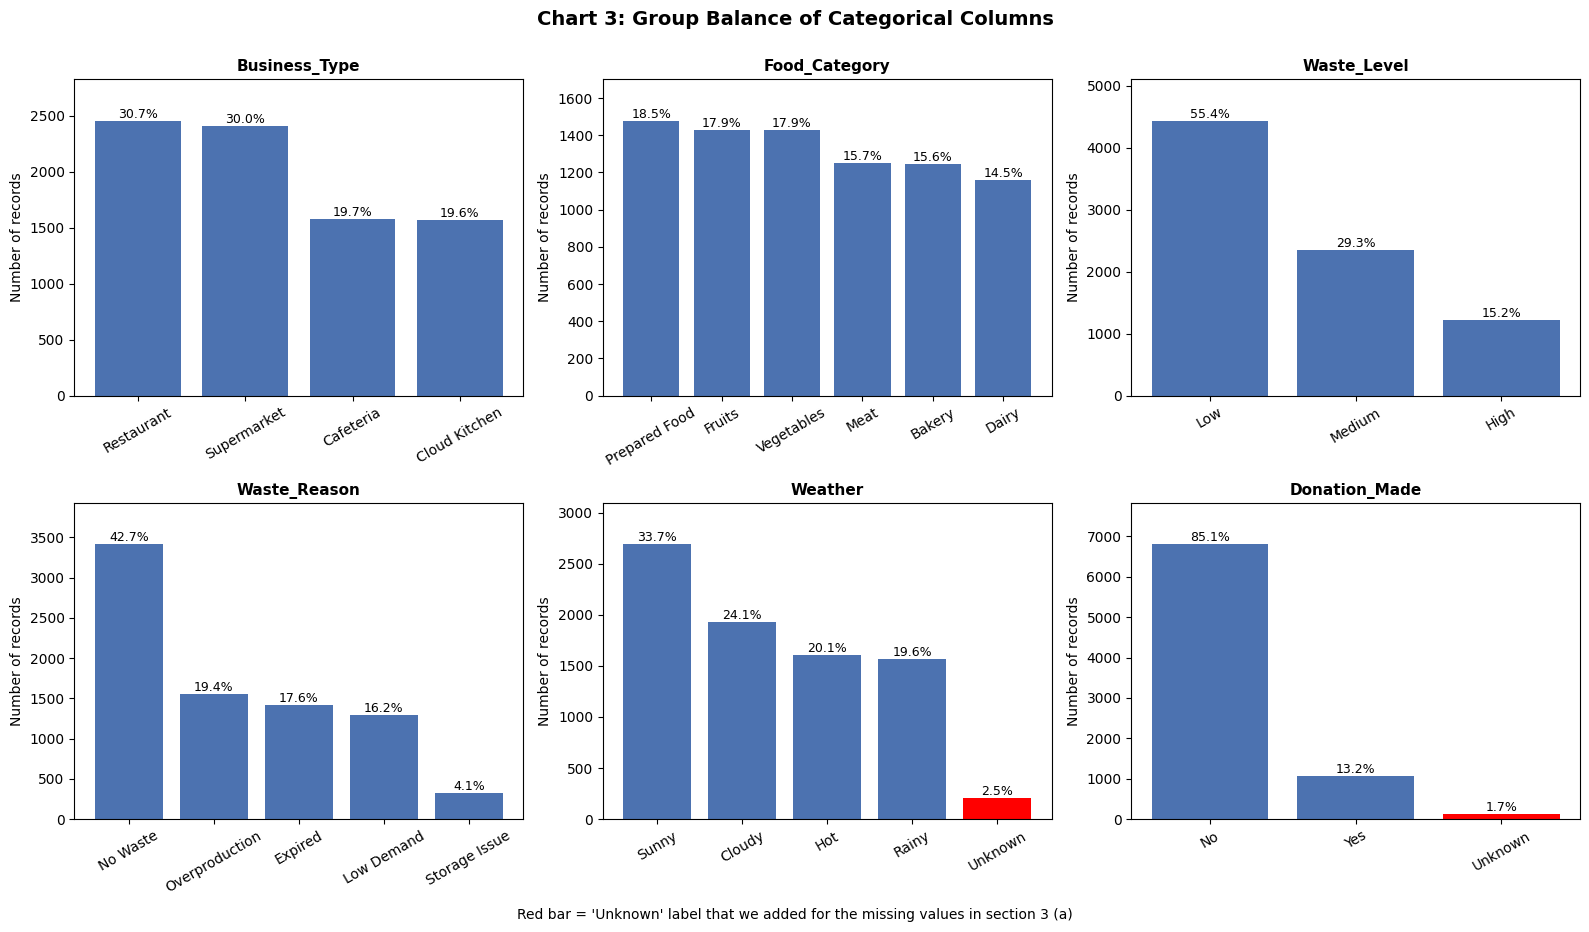

In [37]:
# Chart 3: group balance (value counts) of the categorical columns
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
fig.suptitle("Chart 3: Group Balance of Categorical Columns", fontsize=14, fontweight="bold", y=1.0)

for ax, col in zip(axes.flatten(), balance_cols):
    counts = df[col].astype(str).value_counts()
    colors = ["red" if label == "Unknown" else "#4C72B0" for label in counts.index]   # red = label we added for missing values
    ax.bar(counts.index, counts.values, color=colors)
    ax.set_title(col, fontsize=11, fontweight="bold")
    ax.set_ylabel("Number of records")
    ax.tick_params(axis="x", rotation=30)
    for i, v in enumerate(counts.values):
        ax.text(i, v, f"{v / len(df) * 100:.1f}%", ha="center", va="bottom", fontsize=9)
    ax.set_ylim(0, counts.max() * 1.15)

fig.text(0.5, -0.01, "Red bar = 'Unknown' label that we added for the missing values in section 3 (a)", ha="center", fontsize=10)
plt.tight_layout()
plt.show()

**Observation (Chart 3)**

- **Business_Type** is not equal. Restaurant (30.7%) and Supermarket (30.0%) together make up about 61% of the rows, while Cafeteria (19.7%) and Cloud Kitchen (19.6%) only make up about 39%.
- **Food_Category** is quite balanced. The biggest is Prepared Food (18.5%) and the smallest is Dairy (14.5%), so the ratio is only 1.3.
- **Waste_Level** (our target column) is unbalanced. Low is 55.4%, Medium is 29.3% and High is only 15.2%, a ratio of 3.6. A model could mostly guess "Low" and still look accurate.
- **Waste_Reason** is the most unbalanced. "No Waste" is 42.7% while "Storage Issue" is only 4.1% (329 rows), a ratio of 10.4.
- **Donation_Made** is also unbalanced. "No" is 85.1% and "Yes" is only 13.2% (ratio 6.4).
- **Weather** has a smaller imbalance (Sunny 33.7% vs Rainy 19.6%). The red bars are the "Unknown" labels from the missing values, and they are small (Weather 2.5%, Donation_Made 1.7%).

In [38]:
# other sampling checks
print("Rows with no waste (Waste_Quantity = 0):", (df["Waste_Quantity"] == 0).sum(),
      f"({(df['Waste_Quantity'] == 0).mean() * 100:.1f}%)")

per_day = df.groupby("Date").size()
print("\nRecords per day -> min:", per_day.min(), "| max:", per_day.max(), "| average:", round(per_day.mean(), 1))
print("Months covered:", df["Date"].dt.month.nunique(), "| Years covered:", df["Date"].dt.year.nunique())

# does every date have only one weather type? (it should if all businesses are in the same area)
known_weather = df[df["Weather"] != "Unknown"]
weather_per_day = known_weather.groupby("Date", observed=True)["Weather"].nunique()
print("\nDates with more than 1 weather type:", (weather_per_day > 1).sum(), "out of", df["Date"].nunique())

# does the weather change with the months?
display((pd.crosstab(known_weather["Date"].dt.month, known_weather["Weather"], normalize="index") * 100).round(1).head(12))

Rows with no waste (Waste_Quantity = 0): 3415 (42.7%)

Records per day -> min: 9 | max: 38 | average: 21.9
Months covered: 12 | Years covered: 1

Dates with more than 1 weather type: 365 out of 365


Weather,Cloudy,Hot,Rainy,Sunny
Date,,,,
1,23.9,20.1,20.3,35.7
2,25.7,19.5,21.6,33.2
3,22.7,20.7,22.5,34.1
4,25.0,24.3,17.9,32.8
5,24.2,21.0,19.9,34.9
6,21.3,19.5,21.3,37.8
7,29.1,17.9,18.8,34.2
8,25.4,20.1,18.8,35.7
9,24.7,22.5,17.8,35.0


**Observation (Other sampling checks)**

- **Many zero-waste rows:** 42.7% of the rows have no waste. If we calculate the average waste with all rows, the waste will look smaller than it really is on the days when waste happens.
- **Uneven and short coverage:** The number of records per day goes from 9 to 38, so some days have more than 4 times more records than others. The data also covers only 1 year (2025), so we cannot see year-to-year changes.
- **Weather looks random:** Every one of the 365 dates has more than 1 type of weather, and the weather share is almost the same in every month (for example, "Hot" is about 18% to 24% in every month, even in January). In real life, businesses in the same area have the same weather on the same day, and the dataset has no location column to explain the differences. This is one more sign that the data is simulated, so we should be careful when saying that weather affects demand or waste.

**How we would handle the bias risks**

| Risk | Evidence | How we would handle it |
|---|---|---|
| Synthetic data / unknown sampling | Data is simulated and the way the rows were sampled is not explained. Weather does not follow the dates | Treat it as practice data and do not use it for real decisions. If used for real, check the results with real outlet records first and state this limitation clearly |
| Uneven business types | Restaurant + Supermarket about 61% vs Cafeteria + Cloud Kitchen about 39% | Report the results for each Business_Type, not only the overall result. Use a stratified split for train/test and apply weights if we need equal groups |
| Unbalanced target (Waste_Level) | Low 55.4%, Medium 29.3%, High 15.2% | Use a stratified split, class weights or oversampling (on the training data only). Judge with recall/F1 for every class, not only accuracy |
| Many zero-waste rows | 42.7% of rows have Waste_Quantity = 0 | Analyse the rows with waste separately, or show results with and without the zero-waste rows |
| Very small groups | "Storage Issue" is 4.1% (329 rows), donation "Yes" is 13.2% | Always show the group counts, avoid strong conclusions from small groups, and collect more data for them |
| "Unknown" labels | Weather 2.5%, Donation_Made 1.7% | Keep them as a separate group and leave them out when comparing groups |
| Filled-in values | Medians were used to fill the missing values, which can make the data look less spread out | Use the `_was_missing` flags to run the analysis again without the filled rows and compare the results |
| Limited coverage | Only 1 year, no outlet ID, no location, 9 to 38 records per day | Collect more years and add an outlet ID so we can study seasons and compare outlets fairly |

**Summary:** The data has no personal information or protected groups (such as age, gender or race), so there is no person-level fairness problem. The bias risk is about the business groups: if a model is trained mostly on Restaurants and Supermarkets, it may work worse for Cafeterias and Cloud Kitchens. Together with the unbalanced target and the unrealistic weather, this means the dataset is fine for practising data profiling, but we should be careful before using any result from it to make real decisions.

# Conclusion

Overall, the data profiling process helped us identify and handle several data quality issues in the Food Waste Management dataset. The original dataset contained 8,000 records with missing values in five columns. We handled these using median imputation, "Unknown" labels, and missing-value flags without removing any rows.

We also detected outliers in numerical attributes such as Remaining_Stock and Waste_Quantity. These values were kept because they may represent important food waste situations. Besides that, we found no exact duplicate records, corrected 104 inconsistent Waste_Level labels, converted unsuitable data types, and flagged 70 suspicious storage temperature records.

After cleaning, the dataset is more consistent and suitable for exploratory analysis and practising food waste monitoring. However, some limitations remain, including its synthetic nature, unbalanced categories, imputed values, and uncertain Waste_Level thresholds. Therefore, the dataset is useful for this assignment but real-world data and further validation would be needed before using it for actual business decisions.